# A3 – Detección de fugas de ingresos

El enunciado pide cuatro cosas para A3:

1. El patrón de devoluciones: si hay productos, categorías o segmentos con tasas anómalas, y si hay clientes que devuelven una y otra vez.
2. Cruzar el CRM con las compras posteriores: ¿los clientes con quejas no resueltas compran menos después?
3. Los clientes en riesgo de fuga (*churn*): definir una medida de inactividad y encontrar el segmento de mayor valor en riesgo.
4. El impacto económico de las fugas, expresado en ingresos perdidos proyectados a 6 meses.

Usamos los datos limpios de A1 (`cargar_limpio`) y el segmento que trae el archivo. El segmento calculado en A1 (`segmento_rfm`) queda como contraste. Las decisiones están explicadas en `DECISIONES.md` (A3.1 a A3.5).

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from src.carga import cargar_limpio, RAIZ, DIAS_INACTIVO, MOTIVOS_PERDIDA

d = cargar_limpio()
cli = d["clientes"]
trx = d["transacciones"].merge(cli[["cliente_id", "segmento"]], on="cliente_id")
dev = d["devoluciones"]
crm = d["interacciones_crm"]
FIN = trx.fecha.max()
FIG = RAIZ / "figures"
rng = np.random.default_rng(2026)

# Colores (paleta de referencia de la guía de visualización)
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#8a8984"
TEXTO, TEXTO_2, FONDO = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ecebe7", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def miles(x):
    # 1.234 en vez de 1,234
    return f"{x:,.0f}".replace(",", ".")

print("Datos del", trx.fecha.min().date(), "al", FIN.date())

Datos del 2023-01-01 al 2024-12-31


## 1. Devoluciones: ¿dónde se devuelve más de lo normal?

Comparamos la tasa de devolución (ventas devueltas / ventas) de cada grupo con la tasa global.

**Cuándo decimos que una tasa es anómala (A3.1):** cuando la diferencia con la tasa de referencia no se explica por azar. Usamos una prueba binomial y, como comparamos muchos grupos a la vez (318 productos), corregimos con Benjamini-Hochberg. Sin esa corrección, de 318 productos saldrían unos 16 "anómalos" por pura casualidad. También mostramos el intervalo de confianza del 95% (Wilson) de cada tasa.

In [2]:
tasa_global = trx.devuelta.mean()
print(f"Tasa global de devolución: {tasa_global:.1%} ({miles(trx.devuelta.sum())} de {miles(len(trx))} ventas)")
print("Por semestre:", (trx.groupby(trx.fecha.dt.year.astype(str) + "-S" + (1 + (trx.fecha.dt.month > 6)).astype(str))
                        .devuelta.mean() * 100).round(1).to_dict())

def tasas(col, ref=None, n_min=0):
    # ref: tasa con la que se compara cada grupo (por defecto, la global)
    g = trx.groupby(col).devuelta.agg(ventas="size", devueltas="sum")
    g = g[g.ventas >= n_min]
    g["tasa %"] = 100 * g.devueltas / g.ventas
    lo, hi = proportion_confint(g.devueltas, g.ventas, method="wilson")
    g["IC 95%"] = [f"{100 * a:.1f} – {100 * b:.1f}" for a, b in zip(lo, hi)]
    r = pd.Series(tasa_global, index=g.index) if ref is None else ref
    g["p"] = [stats.binomtest(int(k), int(n), p).pvalue for k, n, p in zip(g.devueltas, g.ventas, r)]
    g["anómala"] = multipletests(g.p, method="fdr_bh")[0]
    return g.sort_values("tasa %", ascending=False)

for col in ["categoria", "segmento", "canal", "metodo_pago"]:
    print()
    print(tasas(col).round({"tasa %": 1, "p": 4}).to_string())

Tasa global de devolución: 13.4% (6.724 de 50.000 ventas)
Por semestre: {'2023-S1': 13.4, '2023-S2': 13.4, '2024-S1': 13.3, '2024-S2': 13.6}

                     ventas  devueltas  tasa %       IC 95%    p  anómala
categoria                                                                
Ropa_y_Calzado         8311       1810    21.8  20.9 – 22.7  0.0     True
Electrónica            8419       1486    17.7  16.9 – 18.5  0.0     True
Deportes               8311        887    10.7  10.0 – 11.4  0.0     True
Belleza_y_Salud        8287        878    10.6  10.0 – 11.3  0.0     True
Alimentos_y_Bebidas    8317        845    10.2   9.5 – 10.8  0.0     True
Hogar_y_Deco           8355        818     9.8   9.2 – 10.4  0.0     True

            ventas  devueltas  tasa %       IC 95%       p  anómala
segmento                                                           
Esporádico    7792       1065    13.7  12.9 – 14.4  0.5724    False
Frecuente    25458       3436    13.5  13.1 – 13.9  0.8184   

Solo las **categorías** se salen de lo normal: Ropa y Calzado y Electrónica devuelven mucho más que la media, y las otras cuatro, menos. Ni el segmento, ni el canal, ni el medio de pago cambian la tasa.

Ahora bajamos a subcategorías y productos. La pregunta importante es si hay productos raros **dentro de su categoría**: un pantalón que se devuelve al 22% no es raro si toda la ropa se devuelve al 22%.

In [3]:
prod_global = tasas("producto_id")
print(f"Productos anómalos comparados con la tasa global: {prod_global.anómala.sum()} de {len(prod_global)}")
print("  ¿De qué categoría son?", trx.drop_duplicates("producto_id").set_index("producto_id")
      .categoria.reindex(prod_global[prod_global.anómala].index).value_counts().to_dict())

# Misma prueba, pero comparando cada producto y subcategoría con la tasa de su propia categoría
tasa_cat = trx.groupby("categoria").devuelta.mean()
ref_prod = trx.drop_duplicates("producto_id").set_index("producto_id").categoria.map(tasa_cat)
prod_cat = tasas("producto_id", ref=ref_prod.sort_index())
ref_sub = trx.drop_duplicates("subcategoria").set_index("subcategoria").categoria.map(tasa_cat)
sub_cat = tasas("subcategoria", ref=ref_sub.sort_index())
print(f"Productos anómalos comparados con su categoría: {prod_cat.anómala.sum()} de {len(prod_cat)} "
      f"(p más bajo: {prod_cat.p.min():.4f})")
print(f"Subcategorías anómalas comparadas con su categoría: {sub_cat.anómala.sum()} de {len(sub_cat)}")
print("Ventas por producto (mín / mediana / máx):", prod_cat.ventas.min(), prod_cat.ventas.median(), prod_cat.ventas.max())

Productos anómalos comparados con la tasa global: 51 de 318
  ¿De qué categoría son? {'Ropa_y_Calzado': 32, 'Electrónica': 6, 'Deportes': 4, 'Hogar_y_Deco': 4, 'Alimentos_y_Bebidas': 3, 'Belleza_y_Salud': 2}


Productos anómalos comparados con su categoría: 0 de 318 (p más bajo: 0.0035)
Subcategorías anómalas comparadas con su categoría: 0 de 24
Ventas por producto (mín / mediana / máx): 115 158.0 190


Los 51 productos "anómalos" son solo el reflejo de su categoría: al compararlos con su propia categoría, no queda ninguno. Lo mismo pasa con las subcategorías. **El problema está en la categoría completa, no en productos concretos.** Todos los productos tienen más de 100 ventas, así que no es falta de datos.

¿Por qué devuelven tanto Ropa y Calzado y Electrónica? Miramos los motivos.

In [4]:
motivos = pd.crosstab(dev.categoria, dev.motivo)
pct = (100 * motivos.div(motivos.sum(axis=1), axis=0)).round(1)
print("% de las devoluciones de cada categoría, por motivo:")
print(pct.to_string())

# Tasa de devolución por motivo: devoluciones por cada 100 ventas de la categoría
ventas_cat = trx.groupby("categoria").size()
por_100 = (100 * motivos.div(ventas_cat, axis=0)).round(2)
print("\nDevoluciones por cada 100 ventas, por motivo:")
print(por_100.to_string())

resto = ~por_100.index.isin(["Ropa_y_Calzado", "Electrónica"])
print("\nExceso de Ropa y Electrónica sobre la media de las otras 4 categorías (puntos por cada 100 ventas):")
print((por_100.loc[["Ropa_y_Calzado", "Electrónica"]] - por_100[resto].mean()).round(2).to_string())
print("\nDías entre compra y devolución (mediana):", dev.dias_a_devolucion.median(),
      "| máximo:", dev.dias_a_devolucion.max())
print("Monto devuelto / monto de la venta:", (dev.monto_devuelto / dev.monto_neto).round(3).unique())

% de las devoluciones de cada categoría, por motivo:
motivo               Cambio_de_opinion  Demora_en_entrega  Error_en_pedido  Fraude_reportado  No_cumple_expectativas  Producto_defectuoso  Talla_incorrecta
categoria                                                                                                                                                  
Alimentos_y_Bebidas                4.7               10.8             13.1               5.4                    39.2                 26.7               0.0
Belleza_y_Salud                    5.8                9.9             14.2               4.3                    37.2                 28.5               0.0
Deportes                           7.1                8.7             14.2               4.1                    36.4                 29.5               0.0
Electrónica                        6.1               10.6             13.1               3.9                    38.9                 27.5               0.0
Hogar_y_Dec

Los motivos explican la diferencia. En Ropa y Calzado, el exceso viene de la talla incorrecta (un motivo que solo existe en esa categoría) y de los productos defectuosos. En Electrónica, de "no cumple expectativas" y también de los defectuosos. Son problemas de producto y de información al cliente, no de un canal ni de un tipo de cliente.

Las devoluciones llegan entre 0 y 30 días después de la compra y siempre reembolsan el 100%.

### ¿Hay clientes que devuelven una y otra vez?

Un cliente que compra mucho tendrá más devoluciones aunque se comporte igual que los demás. Por eso no basta con contar devoluciones: hay que compararlas con lo que se esperaría por azar.

**Cómo lo medimos (A3.2):** simulamos 1.000 veces las devoluciones de cada cliente, usando sus compras reales y la tasa de devolución de la categoría de cada compra. Si en los datos reales hay muchos más clientes con 3, 4 o 5 devoluciones que en las simulaciones, existen "devolvedores" habituales.

In [5]:
cod, ids = pd.factorize(trx.cliente_id)
prob = trx.categoria.map(tasa_cat).to_numpy()
n_max = 12
real = np.bincount(np.bincount(cod, weights=trx.devuelta.to_numpy()).astype(int), minlength=n_max)[:n_max]
sims = np.array([np.bincount(np.bincount(cod, weights=rng.random(len(prob)) < prob).astype(int), minlength=n_max)[:n_max]
                 for _ in range(1000)])
comp = pd.DataFrame({"clientes reales": real, "esperados por azar": sims.mean(0).round(1),
                     "rango esperado (1%–99%)": [f"{a:.0f} – {b:.0f}" for a, b in zip(*np.percentile(sims, [1, 99], axis=0))]},
                    index=pd.Index(range(n_max), name="devoluciones"))
print(comp[comp["clientes reales"].gt(0) | comp["esperados por azar"].gt(0.5)].to_string())

tres = (np.bincount(cod, weights=trx.devuelta.to_numpy()) >= 3).sum()
print(f"\nClientes con 3 o más devoluciones: {tres} reales; esperados por azar: {sims[:, 3:].sum(1).mean():.0f}")
fraude = dev[dev.motivo == "Fraude_reportado"].cliente_id.value_counts()
print(f"Fraude: {len(fraude)} clientes con al menos un fraude reportado; con más de uno: {(fraude > 1).sum()}")

              clientes reales  esperados por azar rango esperado (1%–99%)
devoluciones                                                             
0                        3929              3893.5             3818 – 3979
1                        1968              2006.1             1908 – 2089
2                         918               923.7               868 – 984
3                         445               457.3               415 – 504
4                         228               203.3               172 – 235
5                          76                81.0                62 – 100
6                          24                29.3                 18 – 42
7                          13                 9.6                  4 – 17
8                           6                 3.0                   0 – 7
9                           0                 0.8                   0 – 4
10                          1                 0.2                   0 – 2

Clientes con 3 o más devoluciones: 79

**No hay devolvedores habituales.** El número de clientes con 1, 2, 3 o más devoluciones cae siempre dentro de lo que se esperaría por azar. Un cliente tiene muchas devoluciones porque compra mucho, sobre todo ropa y electrónica, no porque devuelva más que los demás. Tampoco hay clientes que repitan fraude: solo 5 tienen más de un fraude reportado.

### Cuánto dinero se va en devoluciones

Cada devolución reembolsa el 100% de la venta. Con la regla de A2.1, si el producto vuelve en buen estado se pierde su margen; si es defectuoso o un fraude, se pierde también su costo.

In [6]:
dv = trx[trx.devuelta]
perdida_dev = (dv.margen_bruto - dv.margen_neto)
t = pd.DataFrame({
    "ventas devueltas": dv.groupby("categoria").monto_neto.sum(),
    "margen perdido": perdida_dev.groupby(dv.categoria).sum(),
})
t["% del margen perdido"] = 100 * t["margen perdido"] / t["margen perdido"].sum()
t["% de las ventas totales"] = 100 * trx.groupby("categoria").monto_neto.sum() / trx.monto_neto.sum()
t.loc["Total"] = t.sum()
print(t.round(1).to_string())

# Si Ropa y Electrónica devolvieran a la tasa media de las otras cuatro categorías
tasa_resto = trx[~trx.categoria.isin(["Ropa_y_Calzado", "Electrónica"])].devuelta.mean()
exceso = {}
for c in ["Ropa_y_Calzado", "Electrónica"]:
    x = trx[trx.categoria == c]
    sobra = x.devuelta.mean() - tasa_resto
    exceso[c] = sobra / x.devuelta.mean() * perdida_dev[dv.categoria == c].sum()
print(f"\nTasa de devolución de las otras 4 categorías: {tasa_resto:.1%}")
print(f"Margen perdido por devoluciones en 2 años: {miles(perdida_dev.sum())}")
print("Margen perdido por el exceso de devoluciones (2 años):", {k: miles(v) for k, v in exceso.items()},
      "| total:", miles(sum(exceso.values())))

                     ventas devueltas  margen perdido  % del margen perdido  % de las ventas totales
categoria                                                                                           
Alimentos_y_Bebidas           42909.9         20843.1                   1.8                      2.4
Belleza_y_Salud               79804.9         48417.3                   4.1                      4.3
Deportes                     271614.9        150042.3                  12.6                     14.9
Electrónica                 1398217.4        562833.2                  47.4                     44.1
Hogar_y_Deco                 420947.5        218480.8                  18.4                     25.7
Ropa_y_Calzado               320971.6        186482.0                  15.7                      8.7
Total                       2534466.2       1187098.7                 100.0                    100.0

Tasa de devolución de las otras 4 categorías: 10.3%
Margen perdido por devoluciones en 2 a

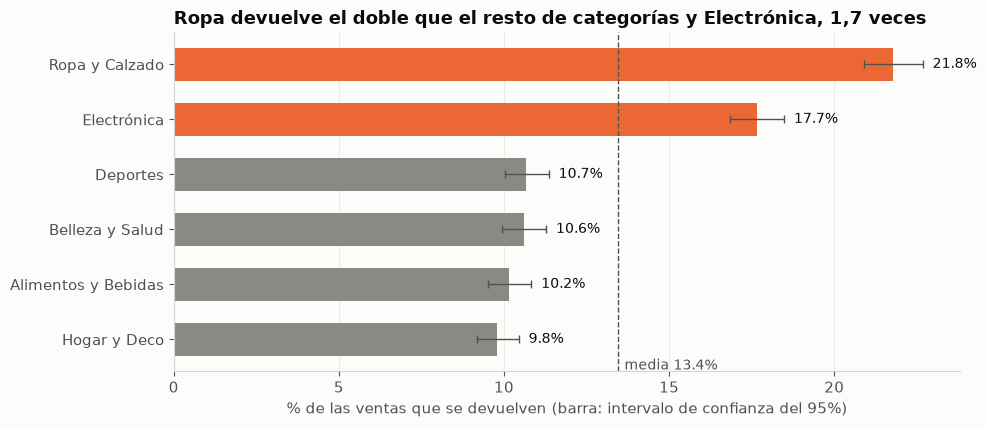

In [7]:
# Gráfico: tasa de devolución por categoría con IC 95%
t = tasas("categoria").sort_values("tasa %")
lo, hi = (np.asarray(x) for x in proportion_confint(t.devueltas, t.ventas, method="wilson"))
y = np.arange(len(t))
alta = t.index.isin(["Ropa_y_Calzado", "Electrónica"])
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.barh(y, t["tasa %"], color=np.where(alta, NARANJA, GRIS), height=0.6)
ax.errorbar(t["tasa %"], y, xerr=[t["tasa %"] - 100 * lo, 100 * hi - t["tasa %"]], fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
ax.axvline(100 * tasa_global, color=TEXTO_2, ls="--", lw=1)
ax.text(100 * tasa_global + 0.2, -0.55, f"media {100 * tasa_global:.1f}%", color=TEXTO_2, fontsize=10)
for i, v in enumerate(t["tasa %"]):
    ax.text(100 * hi[i] + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_yticks(y, [c.replace("_", " ") for c in t.index])
ax.set_xlabel("% de las ventas que se devuelven (barra: intervalo de confianza del 95%)")
ax.set_title("Ropa devuelve el doble que el resto de categorías y Electrónica, 1,7 veces")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_devoluciones_categoria.png", dpi=150)
plt.show()

## 2. Quejas sin resolver: ¿los clientes compran menos después?

**Qué comparamos (A3.3):** para cada queja contamos las compras del cliente en los 90 días **antes** y en los 90 días **después**. Solo usamos quejas con 90 días de datos a cada lado.

**Por qué no basta con mirar el "después":** después de cualquier contacto con atención al cliente podría haber una caída normal (por ejemplo, porque el cliente acababa de comprar). Por eso comparamos el **cambio** de los clientes con quejas sin resolver con el **cambio** de los clientes con quejas resueltas (diferencia en diferencias). Si la queja sin resolver espanta al cliente, su caída debería ser mayor.

In [8]:
print("Contactos por tipo y resolución:")
print(pd.crosstab(crm.tipo, crm.resolucion, margins=True).to_string())
print("\nTiempo de respuesta (mediana, horas) por resolución:", crm.groupby("resolucion").tiempo_respuesta_hrs.median().to_dict())

V = 90
c = crm[((crm.fecha - trx.fecha.min()).dt.days >= V) & ((FIN - crm.fecha).dt.days >= V)].copy()
c = c[c.cliente_id.isin(cli.loc[~cli.sin_compras, "cliente_id"])]
pares = c[["interaccion_id", "cliente_id", "fecha"]].merge(trx[["cliente_id", "fecha", "monto_neto"]],
                                                           on="cliente_id", suffixes=("", "_compra"))
dias = (pares.fecha_compra - pares.fecha).dt.days
pares["antes"] = dias.between(-V, -1)
pares["despues"] = dias.between(1, V)
conteo = pares.groupby("interaccion_id").agg(compras_antes=("antes", "sum"), compras_despues=("despues", "sum"),
                                             gasto_antes=("monto_neto", lambda s: s[pares.loc[s.index, "antes"]].sum()),
                                             gasto_despues=("monto_neto", lambda s: s[pares.loc[s.index, "despues"]].sum()))
c = c.join(conteo, on="interaccion_id").merge(cli[["cliente_id", "segmento"]], on="cliente_id")
c["cambio"] = c.compras_despues - c.compras_antes
q = c[c.tipo == "queja"]

orden = ["resuelto", "parcialmente_resuelto", "escalado", "sin_resolver"]
r = q.groupby("resolucion")[["compras_antes", "compras_despues", "cambio", "gasto_antes", "gasto_despues"]].mean().reindex(orden)
r.insert(0, "quejas", q.resolucion.value_counts())
print(f"\nQuejas con 90 días de datos a cada lado: {len(q)}. Promedio por queja:")
print(r.round(2).to_string())

Contactos por tipo y resolución:
resolucion       escalado  parcialmente_resuelto  resuelto  sin_resolver   All
tipo                                                                          
consulta              139                    320       821           216  1496
felicitacion           26                     49       122            36   233
queja                 471                    306       805           499  2081
soporte_tecnico        63                    182       483           146   874
All                   699                    857      2231           897  4684

Tiempo de respuesta (mediana, horas) por resolución: {'escalado': 11.5, 'parcialmente_resuelto': 11.7, 'resuelto': 12.3, 'sin_resolver': 12.2}



Quejas con 90 días de datos a cada lado: 1517. Promedio por queja:
                       quejas  compras_antes  compras_despues  cambio  gasto_antes  gasto_despues
resolucion                                                                                       
resuelto                  583           0.97             0.95   -0.02       312.18         341.77
parcialmente_resuelto     221           1.02             0.87   -0.15       345.28         303.26
escalado                  340           0.96             0.98    0.01       323.26         352.65
sin_resolver              373           0.98             0.92   -0.06       347.27         315.11


In [9]:
# Diferencia en diferencias con IC: cambio de cada grupo menos el cambio de las resueltas.
# Bootstrap por cliente (un cliente puede tener varias quejas).
def did(df):
    m = df.groupby("resolucion").cambio.mean()
    return m.reindex(orden[1:]) - m["resuelto"]

clientes_q = q.cliente_id.unique()
por_cliente = {k: g for k, g in q.groupby("cliente_id")}
boot = []
for _ in range(1000):
    muestra = pd.concat([por_cliente[k] for k in rng.choice(clientes_q, len(clientes_q))])
    boot.append(did(muestra))
boot = pd.DataFrame(boot)
res = pd.DataFrame({"diferencia": did(q), "IC 2,5%": boot.quantile(0.025), "IC 97,5%": boot.quantile(0.975)})
print("Cambio en compras (90 días) comparado con las quejas resueltas:")
print(res.round(3).to_string())

# Lo mismo con regresión, dejando fijo el segmento y con errores agrupados por cliente
modelo = smf.ols('cambio ~ C(resolucion, Treatment("resuelto")) + C(segmento)', data=q).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(q.cliente_id)[0]})
print()
print(modelo.summary2().tables[1].iloc[1:4, [0, 3, 4, 5]].round(3).to_string())

Cambio en compras (90 días) comparado con las quejas resueltas:
                       diferencia  IC 2,5%  IC 97,5%
resolucion                                          
parcialmente_resuelto      -0.125   -0.334     0.082
escalado                    0.039   -0.153     0.240
sin_resolver               -0.035   -0.211     0.132

                                                               Coef.  P>|z|  [0.025  0.975]
C(resolucion, Treatment("resuelto"))[T.escalado]               0.040  0.676  -0.148   0.228
C(resolucion, Treatment("resuelto"))[T.parcialmente_resuelto] -0.118  0.274  -0.330   0.093
C(resolucion, Treatment("resuelto"))[T.sin_resolver]          -0.034  0.698  -0.208   0.139


In [10]:
# Comprobaciones: ventana de 180 días (¿vuelve a comprar alguna vez?) y tiempo de respuesta
q180 = crm[(crm.tipo == "queja") & ((FIN - crm.fecha).dt.days >= 180) &
           crm.cliente_id.isin(cli.loc[~cli.sin_compras, "cliente_id"])].copy()
p = q180[["interaccion_id", "cliente_id", "fecha"]].merge(trx[["cliente_id", "fecha"]], on="cliente_id", suffixes=("", "_c"))
volvio = p[(p.fecha_c - p.fecha).dt.days.between(1, 180)].interaccion_id.unique()
q180["vuelve_180"] = q180.interaccion_id.isin(volvio)
t = q180.groupby("resolucion").vuelve_180.agg(["mean", "size"]).reindex(orden)
print("% de quejas tras las que el cliente vuelve a comprar en 180 días:")
print((t.assign(mean=100 * t["mean"])).round(1).to_string())
tabla = pd.crosstab(q180.resolucion == "sin_resolver", q180.vuelve_180)
print(f"Sin resolver contra el resto, prueba chi-cuadrado: p = {stats.chi2_contingency(tabla)[1]:.2f}")

m2 = smf.ols("cambio ~ np.log1p(tiempo_respuesta_hrs) + respuesta_atipica + C(segmento)", data=q).fit()
print("\nEfecto del tiempo de respuesta sobre el cambio en compras:")
print(m2.summary2().tables[1].loc[["respuesta_atipica[T.True]", "np.log1p(tiempo_respuesta_hrs)"], ["Coef.", "P>|t|"]].round(3).to_string())

todos = smf.ols('cambio ~ C(tipo, Treatment("consulta")) + C(segmento)', data=c).fit()
print("\nCambio en compras según el tipo de contacto (comparado con consultas):")
print(todos.summary2().tables[1].iloc[1:4, [0, 3]].round(3).to_string())

% de quejas tras las que el cliente vuelve a comprar en 180 días:
                       mean  size
resolucion                       
resuelto               70.8   599
parcialmente_resuelto  70.1   224
escalado               67.7   325
sin_resolver           67.0   348
Sin resolver contra el resto, prueba chi-cuadrado: p = 0.35

Efecto del tiempo de respuesta sobre el cambio en compras:
                                Coef.  P>|t|
respuesta_atipica[T.True]       0.113  0.480
np.log1p(tiempo_respuesta_hrs) -0.019  0.697

Cambio en compras según el tipo de contacto (comparado con consultas):
                                                   Coef.  P>|t|
C(tipo, Treatment("consulta"))[T.felicitacion]    -0.223  0.038
C(tipo, Treatment("consulta"))[T.queja]           -0.069  0.192
C(tipo, Treatment("consulta"))[T.soporte_tecnico] -0.079  0.231


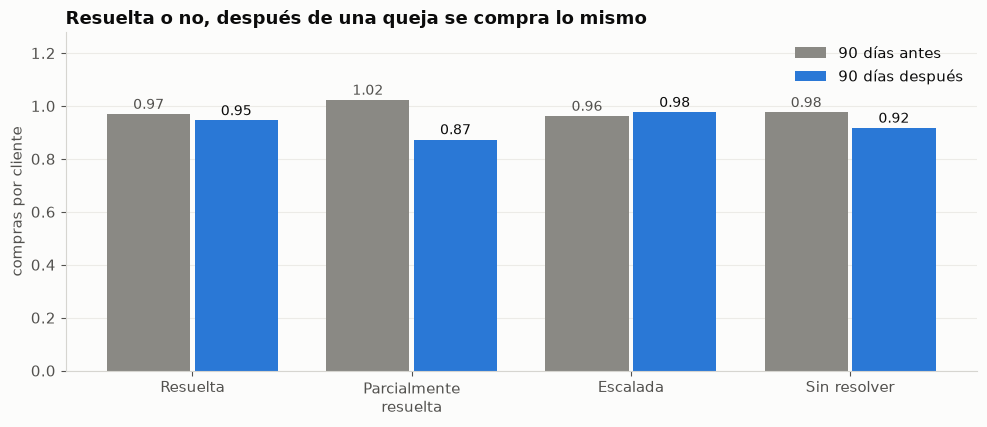

In [11]:
# Gráfico: compras antes y después de la queja, por resolución
etiquetas = {"resuelto": "Resuelta", "parcialmente_resuelto": "Parcialmente\nresuelta", "escalado": "Escalada", "sin_resolver": "Sin resolver"}
x = np.arange(len(orden))
fig, ax = plt.subplots(figsize=(10, 4.4))
ax.bar(x - 0.2, r.compras_antes, width=0.38, color=GRIS, label="90 días antes")
ax.bar(x + 0.2, r.compras_despues, width=0.38, color=AZUL, label="90 días después")
for i, (a, b) in enumerate(zip(r.compras_antes, r.compras_despues)):
    ax.text(i - 0.2, a + 0.02, f"{a:.2f}", ha="center", fontsize=10, color=TEXTO_2)
    ax.text(i + 0.2, b + 0.02, f"{b:.2f}", ha="center", fontsize=10)
ax.set_xticks(x, [etiquetas[o] for o in orden])
ax.set_ylabel("compras por cliente")
ax.set_title("Resuelta o no, después de una queja se compra lo mismo")
ax.legend(frameon=False, loc="upper right")
ax.set_ylim(0, r[["compras_antes", "compras_despues"]].max().max() * 1.25)
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_quejas.png", dpi=150)
plt.show()

## 3. Clientes en riesgo de fuga

**La medida de inactividad (A3.4):** los días que lleva el cliente sin comprar, al cierre de los datos (31-dic-2024). Un cliente está **en riesgo** si pasa de 180 días, el mismo umbral de A1.4 (9 de cada 10 veces que un cliente vuelve, lo hace antes de 162 días).

Pero "en riesgo" no es "perdido": en A1 vimos que el 52% de los que llegan a 180 días vuelve. Así que, para cada cliente en riesgo, estimamos **la probabilidad de que vuelva en los próximos 6 meses**. La sacamos de la historia: nos ponemos en una fecha pasada con 6 meses de datos por delante (30-jun-2024), agrupamos a los clientes por cuánto llevaban sin comprar y por segmento, y contamos qué parte volvió.

Antes de usarla la probamos: con la foto del 31-dic-2023 predecimos lo que pasó en el primer semestre de 2024 y lo comparamos con lo que pasó de verdad.

In [12]:
TRAMOS, NOMBRES = [-1, 90, 180, 270, 10_000], ["0-90", "91-180", "181-270", "más de 270"]
segmento = cli.set_index("cliente_id").segmento
H = pd.Timedelta(days=182)

def foto(corte):
    # Situación de cada cliente en la fecha de corte, y lo que hizo en los 6 meses siguientes
    h = trx[trx.fecha <= corte]
    f = h.groupby("cliente_id").agg(primera=("fecha", "min"), ultima=("fecha", "max"), gasto=("monto_neto", "sum"))
    f["dias_sin_comprar"] = (corte - f.ultima).dt.days
    f["tramo"] = pd.cut(f.dias_sin_comprar, TRAMOS, labels=NOMBRES)
    f["segmento"] = segmento.reindex(f.index)
    # gasto por semestre desde su primera compra (mínimo un semestre)
    f["gasto_semestral"] = f.gasto / np.maximum(1, (corte - f.primera).dt.days / 182.5)
    futuro = trx[(trx.fecha > corte) & (trx.fecha <= corte + H)]
    f["vuelve"] = f.index.isin(futuro.cliente_id)
    f["gasto_6m"] = futuro.groupby("cliente_id").monto_neto.sum().reindex(f.index).fillna(0)
    return f

f23, f24, hoy = foto(pd.Timestamp("2023-12-31")), foto(pd.Timestamp("2024-06-30")), foto(FIN)

# El 52% de A1 cuenta cada vez que un cliente cumple 180 días sin comprar. En una foto, el grupo de
# "más de 180" incluye además a clientes que llevan mucho más tiempo, y esos vuelven menos.
for nombre, f in [("31-dic-2023", f23), ("30-jun-2024", f24)]:
    t = f.groupby("tramo", observed=True).vuelve.agg(["mean", "size"])
    print(f"Foto del {nombre}: % que vuelve en 6 meses según días sin comprar")
    print("  ", {k: f"{100 * v:.0f}% (n={n})" for k, (v, n) in t.iterrows()},
          f"| más de 180 días: {100 * f[f.dias_sin_comprar > 180].vuelve.mean():.0f}%")

Foto del 31-dic-2023: % que vuelve en 6 meses según días sin comprar
   {'0-90': '77% (n=3536.0)', '91-180': '62% (n=1433.0)', '181-270': '48% (n=805.0)', 'más de 270': '40% (n=547.0)'} | más de 180 días: 45%
Foto del 30-jun-2024: % que vuelve en 6 meses según días sin comprar
   {'0-90': '77% (n=3576.0)', '91-180': '61% (n=1411.0)', '181-270': '45% (n=814.0)', 'más de 270': '38% (n=1311.0)'} | más de 180 días: 41%


In [13]:
def tabla_retorno(f):
    # Proporción que volvió y lo que gastó al volver, por segmento y tramo (solo clientes con más de 90 días)
    g = f[f.dias_sin_comprar > 90].groupby(["segmento", "tramo"], observed=True)
    t = g.agg(clientes=("vuelve", "size"), vuelve=("vuelve", "mean"))
    v = f[(f.dias_sin_comprar > DIAS_INACTIVO) & f.vuelve]
    # al volver, cuánto gasta en 6 meses comparado con su gasto semestral de antes
    t["k"] = (v.groupby("segmento").gasto_6m.sum() / v.groupby("segmento").gasto_semestral.sum()).reindex(
        t.index.get_level_values(0)).to_numpy()
    return t

def proyectar(f, t):
    f = f[f.dias_sin_comprar > DIAS_INACTIVO].drop(columns=["vuelve", "gasto_6m"]).join(t[["vuelve", "k"]], on=["segmento", "tramo"])
    k_general = t.k.mean()
    f["k"] = f.k.fillna(k_general)            # segmentos donde nadie volvió: k medio
    # tramo sin clientes en la foto histórica: se usa el promedio del segmento con más de 180 días
    por_seg = t[t.index.get_level_values(1) != "91-180"].groupby(level=0).vuelve.mean()
    f["p_vuelve"] = f.vuelve.fillna(f.segmento.map(por_seg)).fillna(0)
    f["gasto_esperado"] = f.p_vuelve * f.k * f.gasto_semestral
    # Cifra principal: si siguiera activo, gastaría lo mismo que venía gastando por semestre.
    # Tope: gastaría como gastan los que vuelven (k veces su gasto semestral).
    f["ingreso_perdido"] = (1 - f.p_vuelve) * f.gasto_semestral
    f["ingreso_perdido_tope"] = (1 - f.p_vuelve) * f.k * f.gasto_semestral
    return f

# Prueba hacia atrás: con lo aprendido el 31-dic-2023, ¿acertamos el primer semestre de 2024?
t23 = tabla_retorno(f23)
prueba = proyectar(f24, t23)
prueba["volvio"] = f24.vuelve.reindex(prueba.index)
c = prueba.groupby("segmento").agg(clientes=("p_vuelve", "size"), vuelve_previsto=("p_vuelve", "mean"),
                                   vuelve_real=("volvio", "mean"), gasto_previsto=("gasto_esperado", "sum"))
c["gasto_real"] = f24.gasto_6m.reindex(prueba.index).groupby(prueba.segmento).sum()
c.loc["Total"] = [len(prueba), prueba.p_vuelve.mean(), prueba.volvio.mean(), c.gasto_previsto.sum(), c.gasto_real.sum()]
print("Prueba: clientes con más de 180 días sin comprar el 30-jun-2024")
print(c.round(3).to_string())
error = c.loc["Total", "gasto_previsto"] / c.loc["Total", "gasto_real"] - 1
print(f"\nError en el gasto total de los 6 meses: {error:+.1%}")
print(f"Los que volvieron gastaron {f24.loc[prueba.index[prueba.volvio], 'gasto_6m'].sum() / prueba.loc[prueba.volvio, 'gasto_semestral'].sum():.2f} "
      "veces su gasto semestral anterior")

Prueba: clientes con más de 180 días sin comprar el 30-jun-2024
            clientes  vuelve_previsto  vuelve_real  gasto_previsto  gasto_real
segmento                                                                      
Esporádico    1150.0            0.537        0.556      270878.019   264199.55
Frecuente      181.0            0.946        0.901      208002.690   156080.59
Inactivo       448.0            0.000        0.000           0.000        0.00
Nuevo          341.0            0.205        0.182       19892.843    24507.95
Premium          5.0            1.000        1.000        8066.120     7951.51
Total         2125.0            0.407        0.409      506839.672   452739.60

Error en el gasto total de los 6 meses: +11.9%
Los que volvieron gastaron 1.41 veces su gasto semestral anterior


La prueba sale bien en lo importante: acertamos qué parte de los clientes en riesgo vuelve (41% previsto contra 41% real), también segmento por segmento. En el gasto de los que vuelven nos pasamos un 12%, sobre todo por los Frecuentes. Por eso, en la sección 4, la versión con *k* se usa solo como tope del rango y no como cifra principal.

Ahora aplicamos lo aprendido con la foto más reciente (30-jun-2024) a los clientes en riesgo de hoy.

In [14]:
t24 = tabla_retorno(f24)
print("% que vuelve en 6 meses, por segmento y días sin comprar (foto del 30-jun-2024):")
print((100 * t24.vuelve.unstack()).round(0).to_string())
print("\nCuánto gasta en 6 meses el que vuelve, comparado con su gasto semestral anterior (k):",
      t24.k.groupby(level=0).first().round(2).to_dict())

riesgo = proyectar(hoy, t24)
riesgo["segmento_rfm"] = cli.set_index("cliente_id").segmento_rfm.reindex(riesgo.index)
assert (riesgo.segmento_rfm == "Inactivo").all()   # mismo umbral que A1.4
print(f"\nClientes en riesgo hoy (más de {DIAS_INACTIVO} días sin comprar): {len(riesgo)} "
      f"de {(~cli.sin_compras).sum()} con compras ({len(riesgo) / (~cli.sin_compras).sum():.0%})")

compras = cli.set_index("cliente_id").n_compras
print("\nEl segmento 'Inactivo' del archivo: n.º de compras de sus clientes ->",
      compras[segmento == "Inactivo"].value_counts().sort_index().to_dict())

% que vuelve en 6 meses, por segmento y días sin comprar (foto del 30-jun-2024):
tramo       91-180  181-270  más de 270
segmento                               
Esporádico    50.0     50.0        59.0
Frecuente     95.0     88.0        96.0
Inactivo       0.0      0.0         0.0
Nuevo         15.0     18.0        18.0
Premium       99.0    100.0         NaN

Cuánto gasta en 6 meses el que vuelve, comparado con su gasto semestral anterior (k): {'Esporádico': 1.38, 'Frecuente': 1.32, 'Inactivo': nan, 'Nuevo': 2.44, 'Premium': 2.76}

Clientes en riesgo hoy (más de 180 días sin comprar): 2647 de 7608 con compras (35%)

El segmento 'Inactivo' del archivo: n.º de compras de sus clientes -> {0: 255, 1: 881}


In [15]:
# Valor en riesgo por segmento, con IC bootstrap (se remuestrean los clientes de la foto
# del 30-jun-2024, se recalcula la tabla de retorno, y se remuestrean los clientes en riesgo)
def valor_por_segmento(f_hist, f_hoy):
    r = proyectar(f_hoy, tabla_retorno(f_hist))
    return r.groupby("segmento")[["ingreso_perdido", "ingreso_perdido_tope"]].sum()

boot = []
for _ in range(300):
    fh = f24.sample(len(f24), replace=True, random_state=rng.integers(1e9))
    fh = fh.reset_index(drop=True)
    fr = hoy.sample(len(hoy), replace=True, random_state=rng.integers(1e9)).reset_index(drop=True)
    boot.append(valor_por_segmento(fh, fr))
boot_tope = pd.DataFrame([b.ingreso_perdido_tope for b in boot]).fillna(0)
boot = pd.DataFrame([b.ingreso_perdido for b in boot]).fillna(0)

v = riesgo.groupby("segmento").agg(en_riesgo=("p_vuelve", "size"), p_vuelve=("p_vuelve", "mean"),
                                   gasto_semestral=("gasto_semestral", "mean"), ingreso_perdido=("ingreso_perdido", "sum"),
                                   tope=("ingreso_perdido_tope", "sum"))
v["por cliente"] = v.ingreso_perdido / v.en_riesgo
v["IC 2,5%"], v["IC 97,5%"] = boot.quantile(0.025), boot.quantile(0.975)
v["% del total"] = 100 * v.ingreso_perdido / v.ingreso_perdido.sum()
v = v.sort_values("ingreso_perdido", ascending=False)
print("Ingresos que dejarían de entrar en los próximos 6 meses por los clientes en riesgo:")
print(v.round({"p_vuelve": 2, "gasto_semestral": 0, "ingreso_perdido": 0, "por cliente": 0,
               "IC 2,5%": 0, "IC 97,5%": 0, "tope": 0, "% del total": 1}).to_string())

print("\nContraste con el segmento calculado en A1: todos los clientes en riesgo son 'Inactivo' calculado;"
      " según el segmento del archivo vienen de:", riesgo.segmento.value_counts().to_dict())

Ingresos que dejarían de entrar en los próximos 6 meses por los clientes en riesgo:
            en_riesgo  p_vuelve  gasto_semestral  ingreso_perdido      tope  por cliente   IC 2,5%  IC 97,5%  % del total
segmento                                                                                                                 
Esporádico       1324      0.56            285.0         169772.0  235131.0        128.0  153683.0  184712.0         46.4
Inactivo          654      0.00            168.0         109619.0  208927.0        168.0   94957.0  124765.0         30.0
Nuevo             488      0.18            183.0          73024.0  178188.0        150.0   62997.0   84591.0         20.0
Frecuente         170      0.90            774.0          13366.0   17680.0         79.0    7758.0   19326.0          3.7
Premium            11      1.00           1248.0              0.0       0.0          0.0       0.0       0.0          0.0

Contraste con el segmento calculado en A1: todos los clientes

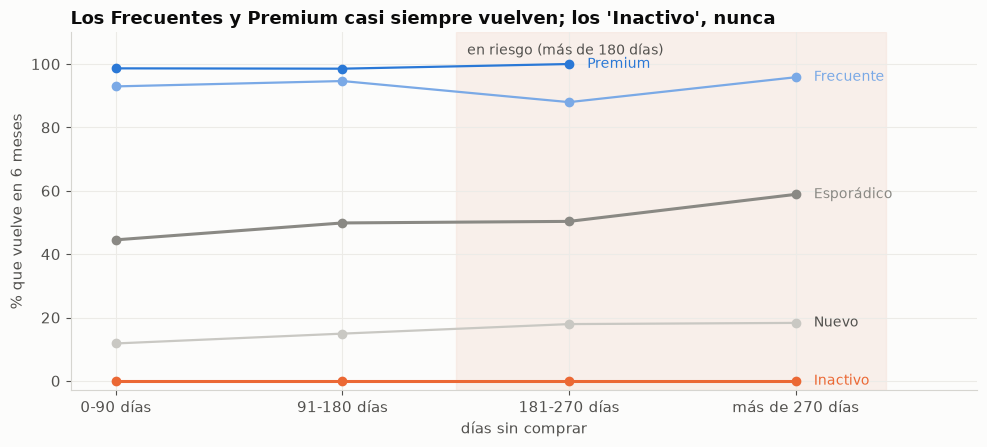

In [16]:
# Gráfico: % que vuelve en 6 meses según días sin comprar, por segmento
segs = ["Premium", "Frecuente", "Esporádico", "Nuevo", "Inactivo"]
colores = {"Premium": AZUL, "Frecuente": "#7aa9e6", "Esporádico": GRIS, "Nuevo": "#c9c8c3", "Inactivo": NARANJA}
tab = 100 * f24.groupby(["segmento", "tramo"], observed=True).vuelve.mean().unstack()
fig, ax = plt.subplots(figsize=(10, 4.6))
x = np.arange(len(NOMBRES))
for s in segs:
    fila = tab.loc[s].reindex(NOMBRES)
    ax.plot(x, fila, marker="o", color=colores[s], lw=2.2 if s in ("Esporádico", "Inactivo") else 1.6)
    ult = fila.last_valid_index()
    ax.text(NOMBRES.index(ult) + 0.08, fila[ult], s, va="center", color=colores[s] if s != "Nuevo" else TEXTO_2, fontsize=10)
ax.axvspan(1.5, 3.4, color="#f6e3da", alpha=0.5, zorder=0)
ax.text(1.55, 103, "en riesgo (más de 180 días)", fontsize=10, color=TEXTO_2)
ax.set_xticks(x, [f"{n} días" for n in NOMBRES])
ax.set_xlim(-0.2, 3.8)
ax.set_ylim(-3, 110)
ax.set_xlabel("días sin comprar")
ax.set_ylabel("% que vuelve en 6 meses")
ax.set_title("Los Frecuentes y Premium casi siempre vuelven; los 'Inactivo', nunca")
fig.tight_layout()
fig.savefig(FIG / "a3_retorno_segmento.png", dpi=150)
plt.show()

## 4. Impacto económico a 6 meses

**Cómo lo calculamos (A3.5):** sumamos las fugas que los datos respaldan, cada una por separado:

- **Clientes en riesgo:** para cada uno, (1 − probabilidad de volver) × lo que venía gastando por semestre. Es una cifra prudente: los clientes que vuelven suelen gastar más que antes (el factor *k* de la sección 3). Esa otra versión, con *k*, la usamos como tope del rango.
- **Devoluciones:** la tasa de devolución del último semestre aplicada a las ventas del último semestre. En ingresos es el monto que se reembolsa; en margen, lo que se pierde según la regla de A2.1. Damos aparte el **exceso** de Ropa y Electrónica, que es la parte que se podría recuperar.
- **Quejas sin resolver:** no suman nada, porque en la sección 2 no encontramos ningún efecto.

No hay doble conteo: la fuga de clientes son ventas que no ocurren; las devoluciones son ventas que sí ocurren y se reembolsan.

In [17]:
# Fuga de clientes. Rango: desde el IC 2,5% de la cifra principal hasta el IC 97,5% del tope
churn = riesgo.ingreso_perdido.sum()
churn_lo, churn_hi = boot.sum(axis=1).quantile(0.025), boot_tope.sum(axis=1).quantile(0.975)
margen_pct = trx.margen_bruto.sum() / trx.monto_neto.sum()

# Devoluciones: último semestre
ult = trx[trx.fecha >= "2024-07-01"]
dev_ingreso = ult.loc[ult.devuelta, "monto_neto"].sum()
dev_margen = (ult.margen_bruto - ult.margen_neto).sum()
lo, hi = proportion_confint(ult.devuelta.sum(), len(ult), method="wilson")
dev_lo, dev_hi = dev_ingreso * lo / ult.devuelta.mean(), dev_ingreso * hi / ult.devuelta.mean()

# Exceso de Ropa y Electrónica sobre la tasa de las otras categorías, último semestre
u = ult[ult.categoria.isin(["Ropa_y_Calzado", "Electrónica"])]
resto_u = ult[~ult.categoria.isin(["Ropa_y_Calzado", "Electrónica"])].devuelta.mean()
fraccion = 1 - resto_u / u.groupby("categoria").devuelta.mean()
exc_ingreso = sum(u.loc[u.devuelta & (u.categoria == c), "monto_neto"].sum() * fraccion[c] for c in fraccion.index)
exc_margen = sum((u.margen_bruto - u.margen_neto)[u.categoria == c].sum() * fraccion[c] for c in fraccion.index)

ventas_sem = ult.monto_neto.sum()
resumen = pd.DataFrame([
    ["Clientes en riesgo que no vuelven", churn, churn_lo, churn_hi, churn * margen_pct],
    ["Devoluciones (todas)", dev_ingreso, dev_lo, dev_hi, dev_margen],
    ["   de ellas, exceso de Ropa y Electrónica", exc_ingreso, np.nan, np.nan, exc_margen],
    ["Quejas sin resolver", 0, np.nan, np.nan, 0],
], columns=["fuga", "ingresos", "desde", "hasta", "margen"]).set_index("fuga")
resumen["% de las ventas del semestre"] = 100 * resumen.ingresos / ventas_sem
print(f"Ventas del último semestre: {miles(ventas_sem)}")
print(resumen.round({"ingresos": 0, "desde": 0, "hasta": 0, "margen": 0, "% de las ventas del semestre": 1}).to_string())
total = churn + dev_ingreso
print(f"\nTotal de fugas a 6 meses (clientes + devoluciones): {miles(total)} en ingresos "
      f"({100 * total / ventas_sem:.1f}% de las ventas de un semestre)")
print(f"Margen de los clientes en riesgo calculado con el margen bruto medio ({margen_pct:.1%}).")

Ventas del último semestre: 4.366.059
                                           ingresos     desde     hasta    margen  % de las ventas del semestre
fuga                                                                                                           
Clientes en riesgo que no vuelven          365781.0  341539.0  844619.0   90648.0                           8.4
Devoluciones (todas)                       645677.0  617762.0  674646.0  288132.0                          14.8
   de ellas, exceso de Ropa y Electrónica  169423.0       NaN       NaN   69042.0                           3.9
Quejas sin resolver                             0.0       NaN       NaN       0.0                           0.0

Total de fugas a 6 meses (clientes + devoluciones): 1.011.458 en ingresos (23.2% de las ventas de un semestre)
Margen de los clientes en riesgo calculado con el margen bruto medio (24.8%).


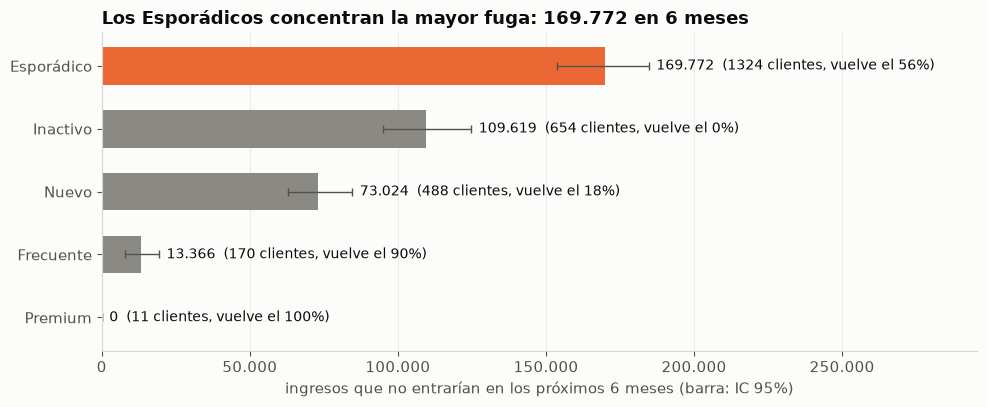

In [18]:
# Gráfico: ingresos perdidos a 6 meses por segmento (clientes en riesgo)
v2 = v.sort_values("ingreso_perdido")
y = np.arange(len(v2))
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(y, v2.ingreso_perdido, color=[NARANJA if s == v2.ingreso_perdido.idxmax() else GRIS for s in v2.index], height=0.6)
ax.errorbar(v2.ingreso_perdido, y, xerr=[(v2.ingreso_perdido - v2["IC 2,5%"]).clip(lower=0), (v2["IC 97,5%"] - v2.ingreso_perdido).clip(lower=0)],
            fmt="none", ecolor=TEXTO_2, capsize=3, lw=1)
for i, (s, fila) in enumerate(v2.iterrows()):
    ax.text(fila["IC 97,5%"] + v2.ingreso_perdido.max() * 0.015, i,
            f"{miles(fila.ingreso_perdido)}  ({int(fila.en_riesgo)} clientes, vuelve el {100 * fila.p_vuelve:.0f}%)",
            va="center", fontsize=10)
ax.set_yticks(y, v2.index)
ax.set_xlim(0, v2["IC 97,5%"].max() * 1.6)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: miles(x)))
ax.set_xlabel("ingresos que no entrarían en los próximos 6 meses (barra: IC 95%)")
ax.set_title(f"Los Esporádicos concentran la mayor fuga: {miles(v.ingreso_perdido.max())} en 6 meses")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "a3_fuga_segmento.png", dpi=150)
plt.show()

In [19]:
# Tablas para el dashboard de Power BI (ver docs/dashboard.md)
from src.powerbi import guardar
guardar(f24.groupby(["segmento", "tramo"], observed=True).vuelve.agg(clientes="size", vuelve="mean").reset_index(),
        "resultado_a3_retorno_segmento_tramo")
guardar(v.reset_index(), "resultado_a3_fuga_segmento")
guardar(riesgo[["segmento", "segmento_rfm", "tramo", "dias_sin_comprar", "gasto_semestral", "p_vuelve", "ingreso_perdido"]]
        .reset_index(), "resultado_a3_clientes_en_riesgo")
guardar(r.reset_index(), "resultado_a3_quejas")
guardar(resumen.reset_index(), "resultado_a3_impacto_6_meses")

## 5. Resumen de A3

**Devoluciones**
- Se devuelve el 13,4% de las ventas, y la tasa no cambia entre semestres (de 13,3% a 13,6%).
- **Solo dos categorías se salen de lo normal:** Ropa y Calzado (21,8%) y Electrónica (17,7%). Las otras cuatro devuelven entre 9,8% y 10,7%. El segmento, el canal y el medio de pago no cambian la tasa.
- No hay productos problemáticos sueltos: 51 productos parecen anómalos frente a la media global, pero ninguno lo es frente a su propia categoría. El problema es de la categoría completa.
- Ropa devuelve de más por **talla incorrecta** y **productos defectuosos**; Electrónica, por **"no cumple expectativas"** y **defectuosos**.
- **No hay devolvedores habituales:** 793 clientes tienen 3 o más devoluciones, y por azar se esperarían 785. Quien devuelve mucho es porque compra mucho. Solo 5 clientes repiten fraude.
- En 2 años, las devoluciones se llevaron 1.187.099 de margen; el 47% es de Electrónica. Si Ropa y Electrónica devolvieran como el resto (10,3%), se habrían salvado 332.533 de margen.

**Quejas sin resolver**
- **No vemos que los clientes con quejas sin resolver compren menos.** En los 90 días siguientes a la queja compran 0,92 veces (antes, 0,98). Los de quejas resueltas pasan de 0,97 a 0,95. La diferencia (−0,03 compras) cabe de sobra en lo que puede ser azar (IC 95%: −0,21 a +0,13).
- Tampoco a 180 días: vuelve a comprar el 67% de los que tuvieron una queja sin resolver y el 71% de los que la tuvieron resuelta (p = 0,35). Ni el tiempo de respuesta ni las respuestas muy lentas cambian nada.
- El enunciado sugiere que las quejas sin resolver espantan clientes. Estos datos no lo muestran.

**Clientes en riesgo**
- **Medida:** días sin comprar al 31-dic-2024. En riesgo = más de 180 días. Hay 2.647 clientes en riesgo, el 35% de los que alguna vez compraron.
- En riesgo no es perdido: de cada 10 clientes en riesgo, unos 4 vuelven en 6 meses. Pero depende mucho del segmento: los Frecuentes y Premium vuelven casi siempre (90% a 100%), los Esporádicos la mitad, los Nuevos el 18% y los "Inactivo" del archivo nunca. En el archivo, "Inactivo" son clientes que compraron una sola vez como mucho.
- La estimación funciona: con los datos de 2023 predijimos que volvería el 41% de los clientes en riesgo a mitad de 2024, y volvió el 41%.
- **El segmento de mayor valor en riesgo es el Esporádico:** 1.324 clientes en riesgo que dejarían de gastar 169.772 en 6 meses (IC 95%: 153.683 a 184.712), el 46% de toda la fuga de clientes. Los Frecuentes en riesgo gastan mucho más cada uno (774 por semestre), pero son solo 170 y el 90% vuelve.

**Impacto económico a 6 meses** (sobre ventas de 4.366.059 en el último semestre)
- **Clientes que no vuelven:** 365.781 en ingresos (rango: 341.539 a 844.619), el 8,4% de las ventas de un semestre. Es una cifra prudente: supone que habrían gastado lo mismo que venían gastando. El tope del rango supone que gastarían como los que sí vuelven.
- **Devoluciones:** 645.677 en ingresos reembolsados (14,8% de las ventas) y 288.132 de margen perdido. De eso, el exceso de Ropa y Electrónica (lo que se podría recuperar) son 169.423 en ingresos y 69.042 de margen.
- **Quejas sin resolver:** 0, porque no encontramos efecto.
- **Total: 1.011.458 en 6 meses, el 23,2% de las ventas de un semestre.** No hay doble conteo: unas son ventas que no ocurren y otras, ventas que ocurren y se reembolsan.

**Títulos de gráfico candidatos para A5**
- "Ropa devuelve el doble que el resto de categorías y Electrónica, 1,7 veces" (`figures/a3_devoluciones_categoria.png`)
- "Resuelta o no, después de una queja se compra lo mismo" (`figures/a3_quejas.png`)
- "Los Frecuentes y Premium casi siempre vuelven; los 'Inactivo', nunca" (`figures/a3_retorno_segmento.png`)
- "Los Esporádicos concentran la mayor fuga: 169.772 en 6 meses" (`figures/a3_fuga_segmento.png`)